# Appendix: a simulated referral world

**Simulated. Not field results.** Nothing on this page was observed in the field. Every number comes from a
simulation in which we invent the truth about each facility, then send simulated patients to them.

**Why simulate?** To answer the question a judge would ask: does the app get more patients to care in time than
sending them to the nearest listing, or to the "best" hospital on paper? Since the true answer is unknown for real
facilities, we invent several hidden truths and check whether the answer changes between them.

**Four hidden truths (scenarios).** Each result is shown for all four, never for one alone:
- **S0, "the text says nothing":** whether a facility offers the service depends only on the service and on whether
  it is public or private. Listing sentences and model scores carry no information. This is where the app can lose.
- **S1, "the model is right":** each facility offers the service with the probability our model gives. This is
  the app's best case, and circular, so it is never shown alone.
- **S2, "from our hand checks":** offer rates by service, by how strong the listing's evidence is, and by whether
  a sentence names another facility, taken from 300 web-checked DEV pairs. It does not use the model's scores.
- **S3, "the data is as bad as the audit says":** S2, plus sentences about other facilities are false, and map
  points the audit flagged (more than 50 km from their PIN code) are really at the other point.

**Policies compared**, each trying at most 3 facilities before calling 108:
- **app:** the app as shipped (online answer; the offline state pack when there is no mobile data), phoning ahead;
- **app_offline:** the state pack only;
- **nearest:** the 3 nearest listings that name the service, no phone call;
- **nearest_call_first:** the same, phoning each one first like the app, so we can tell the value of the ranking
  from the value of calling ahead;
- **best_on_paper:** the 3 highest-scored listings in the state, ignoring distance.

Method, assumptions and honesty rules: [`sim/README.md`](../sim/README.md). Issue #92.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ON_DATABRICKS = "DATABRICKS_RUNTIME_VERSION" in os.environ
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sim" / "run.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

if ON_DATABRICKS:
    dbutils.widgets.text("seeds", "20")  # noqa: F821 (dbutils is predefined on Databricks)
    dbutils.widgets.text("cases_per_seed", "200")  # noqa: F821
    SEEDS = int(dbutils.widgets.get("seeds"))  # noqa: F821
    CASES = int(dbutils.widgets.get("cases_per_seed"))  # noqa: F821
    OUT = Path("/Volumes/workspace/referral_saathi/uploads/sim")
else:  # a modest local run; the environment can raise it
    SEEDS = int(os.environ.get("SIM_SEEDS", "20"))
    CASES = int(os.environ.get("SIM_CASES", "200"))
    OUT = ROOT / "sim" / "out"
OUT.mkdir(parents=True, exist_ok=True)
SCENARIOS = ["S0", "S1", "S2", "S3"]
STATES = ["BIHAR", "UTTAR PRADESH"]
SERVICES = ["dialysis", "trauma_emergency"]
shown = OUT if ON_DATABRICKS else OUT.relative_to(ROOT)
print(f"SIMULATED run: {SEEDS} seeds x {CASES} cases, {STATES}, {SERVICES}, output {shown}")

SIMULATED run: 20 seeds x 200 cases, ['BIHAR', 'UTTAR PRADESH'], ['dialysis', 'trauma_emergency'], output sim/out


## The run

For each seed: one set of simulated patients (origins at PIN code centres in Bihar and Uttar Pradesh), the same for
every policy and every scenario. Each policy picks its facilities once; the scenario's hidden truth then decides
what happens on the phone and at the door. The same coin flips apply to the same patient at the same facility under
every policy (common random numbers), so differences come from the policies. Intervals are 90% seed-bootstrap
intervals.

In [2]:
from sim.run import simulate, sweep_verdicts, table

res = simulate(SCENARIOS, list(range(SEEDS)), CASES, STATES, SERVICES, OUT, n_boot=500, sweep=True, verbose=False)
print("SIMULATED. Parts of the world that are still temporary stand-ins:",
      {k: v for k, v in res["sources"].items() if v == "stub"} or "none")
print(f"{len(res['cases']):,} simulated cases, {len(res['events']):,} simulated events, {res['seconds']:.0f} s")

note: sim.world not found; using the temporary stand-in in sim/_stub_*.py
note: sim.execute not found; using the temporary stand-in in sim/_stub_*.py
note: sim.policies_baseline not found; using the temporary stand-in in sim/_stub_*.py


SIMULATED. Parts of the world that are still temporary stand-ins: {'world': 'stub', 'executor': 'stub', 'baselines': 'stub'}
4,000 simulated cases, 433,420 simulated events, 52 s


## Simulated outcomes, by scenario

*Treated in window*: share of patients treated within the time window (60 min for trauma, 120 min for dialysis).
*Wasted trips*: arrivals turned away. *Unsafe first stop*: the first place travelled to does not exist or does not
offer the service. *Gave up*: three facilities tried without treatment, so the worker calls 108. Both states pooled.

In [3]:
t = table(res["metrics"])
for sc in SCENARIOS:
    print(f"\n=== {sc} (SIMULATED, not field results) ===")
    print(t[t.scenario == sc].drop(columns="scenario").to_string(index=False))


=== S0 (SIMULATED, not field results) ===
         service             policy treated in window %    median min  wasted trips/case  calls/case  unsafe 1st stop %  gave up %  cases
        dialysis                app          73 [71-75]    59 [57-61]               0.36        1.73                4.0       18.0   1904
        dialysis        app_offline          74 [72-76]    57 [55-59]               0.38        1.74                4.0       19.0   1904
        dialysis      best_on_paper          19 [17-22] 284 [269-299]               0.44        0.00                5.0       11.0   1904
        dialysis            nearest          70 [68-72]    53 [50-55]               1.05        0.00                7.0       17.0   1904
        dialysis nearest_call_first          74 [72-76]    57 [55-59]               0.38        1.73                4.0       19.0   1904
trauma_emergency                app          67 [65-69]    42 [41-44]               0.21        1.39                9.0        6.

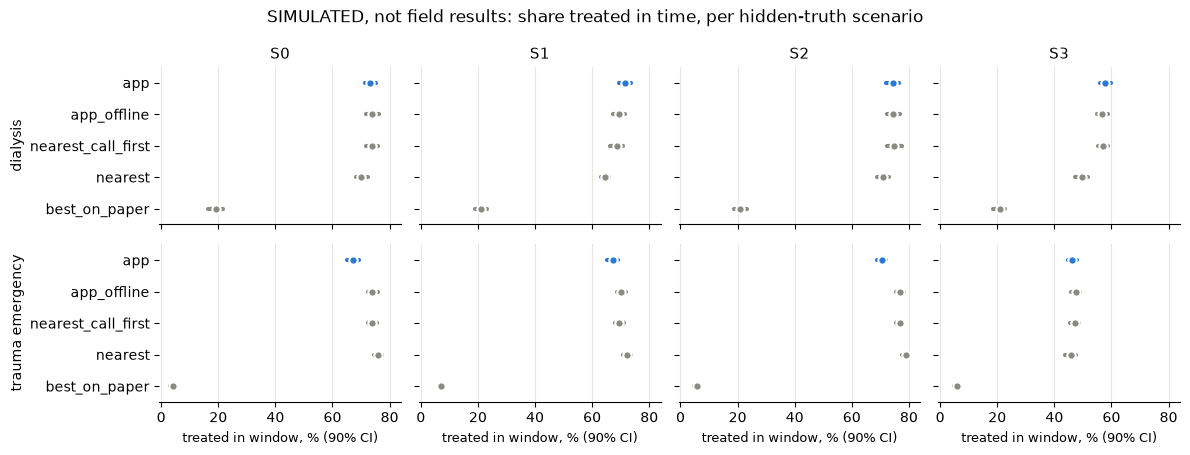

In [4]:
m = res["metrics"]
m = m[m.state == "ALL"]
policies = ["app", "app_offline", "nearest_call_first", "nearest", "best_on_paper"]
fig, axes = plt.subplots(len(SERVICES), len(SCENARIOS), figsize=(12, 4.6), sharex=True, sharey=True)
for i, svc in enumerate(SERVICES):
    for j, sc in enumerate(SCENARIOS):
        ax = axes[i, j]
        d = m[(m.service == svc) & (m.scenario == sc)].set_index("policy").reindex(policies)
        for k, pol in enumerate(policies):
            r = d.loc[pol]
            color = "#2a78d6" if pol == "app" else "#8a8984"
            ax.plot([100 * r.treated_in_window_lo, 100 * r.treated_in_window_hi], [k, k], color=color, lw=3,
                    solid_capstyle="round")
            ax.plot(100 * r.treated_in_window, k, "o", ms=6, color=color, mec="white", mew=1.5)
        ax.set_yticks(range(len(policies)), policies)
        ax.set_ylim(len(policies) - 0.5, -0.5)  # app on top
        ax.grid(axis="x", color="#e6e5e0", lw=0.8)
        ax.set_axisbelow(True)
        for s in ("top", "right", "left"):
            ax.spines[s].set_visible(False)
        if i == 0:
            ax.set_title(sc, fontsize=11)
        if j == 0:
            ax.set_ylabel(svc.replace("_", " "), fontsize=10)
        if i == len(SERVICES) - 1:
            ax.set_xlabel("treated in window, % (90% CI)", fontsize=9)
fig.suptitle("SIMULATED, not field results: share treated in time, per hidden-truth scenario", fontsize=12)
fig.tight_layout()
(OUT / "figures").mkdir(exist_ok=True)
fig.savefig(OUT / "figures" / "sim_treated_in_window.png", dpi=150)
plt.show()

## How much depends on the assumptions

The world needs numbers nobody has measured: how often a facility accepts a patient, how often a listed phone number
reaches it, how often a "yes" on the phone is wrong, and how often a facility is open. Each is set low, middle and
high in turn, with the others at the middle. The table shows **app minus nearest_call_first**, in percentage points of
patients treated in window, with a 90% interval. A level where the interval reaches zero or below is a point where
the app no longer beats the nearest listing called ahead.

In [5]:
s = res["sensitivity"].copy()
s["cell"] = ((100 * s["diff"]).round(1).astype(str) + " [" + (100 * s.diff_lo).round(1).astype(str) + ", "
             + (100 * s.diff_hi).round(1).astype(str) + "]" + s.app_beats.map({True: "", False: " *"}))
print("SIMULATED. app minus nearest_call_first, treated in window (points). * = app does not clearly beat it.")
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(s.pivot_table(index=["knob", "level"], columns=["scenario", "service"], values="cell",
                        aggfunc="first").to_string())
print("\nVerdict at the middle assumptions, and the swept levels where it changes (SIMULATED):")
with pd.option_context("display.width", 250, "display.max_colwidth", 120):
    print(sweep_verdicts(res["sensitivity"]).to_string(index=False))

SIMULATED. app minus nearest_call_first, treated in window (points). * = app does not clearly beat it.
scenario                           S0                                   S1                                       S2                                      S3                    
service                      dialysis     trauma_emergency        dialysis     trauma_emergency            dialysis     trauma_emergency           dialysis    trauma_emergency
knob        level                                                                                                                                                              
accept_p    high    0.3 [-1.2, 1.6] *  -6.6 [-8.1, -5.1] *  3.0 [1.6, 4.6]  -2.5 [-4.0, -0.9] *   0.3 [-0.9, 1.6] *  -6.1 [-7.1, -4.8] *     1.5 [0.2, 3.0]  -0.5 [-2.1, 1.2] *
            low    -0.2 [-1.7, 1.1] *  -5.5 [-6.9, -4.2] *  3.5 [2.0, 5.3]   -1.2 [-2.7, 0.2] *   0.1 [-1.2, 1.6] *  -5.3 [-6.5, -4.1] *  0.3 [-1.2, 1.6] *  -0.6 [-1.8, 0.8] *
all         mid  

## Limits

- **Simulated, not field results.** The hidden truths are built from our own data and 300 hand-checked pairs; a
  real referral network will differ.
- The case generator and the step-by-step executor are still temporary stand-ins (`sim/_stub_execute.py`) until
  `sim/world.py` and `sim/execute.py` land (the cell above prints which parts are stand-ins). They draw patients
  uniformly over PIN codes, not by population, and use straight-line travel estimates.
- Two services and two states only. "App + field reports" and the multi-stop planner route are future work.
- S1 is circular: it assumes the model is right. Read it next to S0, where the listing text says nothing.